# Setup — Imports and reproducibility

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


# Task 1 — Explore the Dataset

In [2]:
# Load Fashion MNIST
(x_full_raw, y_full), (x_test_raw, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Full training images:", x_full_raw.shape)
print("Full training labels:", y_full.shape)
print("Test images:", x_test_raw.shape)
print("Test labels:", y_test.shape)
print("Number of classes:", len(class_names))
print("Class names:", class_names)

# Create one fixed train/validation split (80% / 20%).
# Reuse this exact split for every experiment.
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(x_full_raw))
val_size = int(0.2 * len(x_full_raw))
val_indices = indices[:val_size]
train_indices = indices[val_size:]

x_train_raw, y_train = x_full_raw[train_indices], y_full[train_indices]
x_val_raw, y_val = x_full_raw[val_indices], y_full[val_indices]

# Normalize pixels to [0, 1]
x_train = x_train_raw.astype("float32") / 255.0
x_val = x_val_raw.astype("float32") / 255.0
x_test = x_test_raw.astype("float32") / 255.0

print("Training split:", x_train.shape, y_train.shape)
print("Validation split:", x_val.shape, y_val.shape)
print("Normalized pixel range:", float(x_train.min()), "to", float(x_train.max()))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 12s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Full training images: (60000, 28, 28)
Full training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Number of classes: 10
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Training split: (48000, 28, 28) (48000,)
Validation split: (12000, 28, 28) (12000,)
Normalized pixel range: 0.0 to 1.0


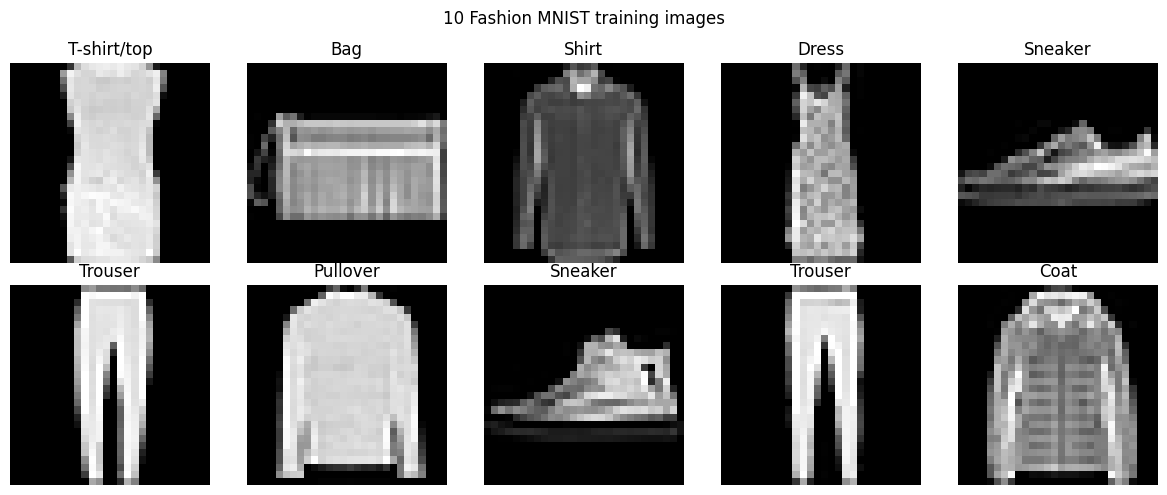

,Class ID,Class name,Training images
0,0,T-shirt/top,4846
1,1,Trouser,4821
2,2,Pullover,4787
3,3,Dress,4820
4,4,Coat,4823
5,5,Sandal,4773
6,6,Shirt,4784
7,7,Sneaker,4791
8,8,Bag,4819
9,9,Ankle boot,4736


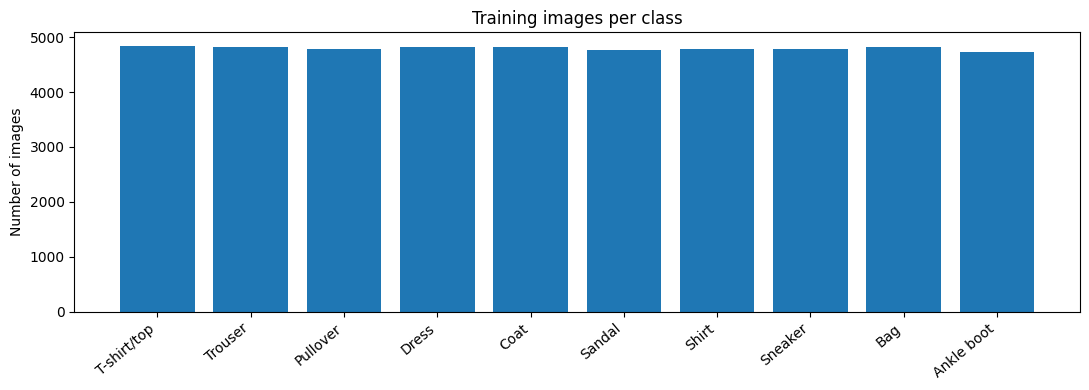

In [3]:
# Display 10 training images with labels
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(class_names[y_train[i]])
    ax.axis("off")
plt.suptitle("10 Fashion MNIST training images")
plt.tight_layout()
plt.show()

# Count examples in each training class
class_counts = np.bincount(y_train, minlength=len(class_names))
count_table = pd.DataFrame({
    "Class ID": range(len(class_names)),
    "Class name": class_names,
    "Training images": class_counts
})
display(count_table)

plt.figure(figsize=(11, 4))
plt.bar(class_names, class_counts)
plt.xticks(rotation=40, ha="right")
plt.ylabel("Number of images")
plt.title("Training images per class")
plt.tight_layout()
plt.show()

## Why normalize ? Is the dataset balanced ?
ormalizing scales the pixel values from the range 0–255 down to 0.0–1.0. This ensures that all inputs are on a similar small scale, which helps the gradient descent algorithm converge much faster and smoother during training and prevents numerical instabilities caused by large values.

## Is the dataset balanced ?

Yes, the dataset is balanced. As shown in the class distribution table and bar chart, each of the 10 clothing classes has a nearly equal number of training images (ranging closely between 4,700 and 4,800 samples per class).

# Shared helper functions
The helper below builds the required baseline architecture and allows experiments to change one setting at a time. Each call creates a fresh model.

In [4]:
def build_model(hidden_units=32, activation="relu", optimizer=None):
    if optimizer is None:
        optimizer = keras.optimizers.Adam(learning_rate=0.001)

    model = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(hidden_units, activation=activation),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def train_fresh_model(
    name,
    hidden_units=32,
    activation="relu",
    optimizer=None,
    epochs=10,
    batch_size=32,
    callbacks=None,
    verbose=0
):
    model = build_model(
        hidden_units=hidden_units,
        activation=activation,
        optimizer=optimizer
    )
    start = time.perf_counter()
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks or [],
        verbose=verbose
    )
    elapsed = time.perf_counter() - start

    best_val_accuracy = max(history.history["val_accuracy"])
    best_val_loss = min(history.history["val_loss"])
    final_val_accuracy = history.history["val_accuracy"][-1]

    result = {
        "name": name,
        "model": model,
        "history": history,
        "epochs_trained": len(history.history["loss"]),
        "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss,
        "final_val_accuracy": final_val_accuracy,
        "seconds": elapsed,
        "hidden_units": hidden_units,
        "activation": activation,
        "batch_size": batch_size,
    }
    print(
        f"{name}: epochs={result['epochs_trained']}, "
        f"best val_accuracy={best_val_accuracy:.4f}, "
        f"best val_loss={best_val_loss:.4f}, "
        f"time={elapsed:.1f}s"
    )
    return result


def plot_history(history, title="Training history"):
    h = history.history
    epochs_axis = range(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs_axis, h["loss"], label="Training loss")
    axes[0].plot(epochs_axis, h["val_loss"], label="Validation loss")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(epochs_axis, h["accuracy"], label="Training accuracy")
    axes[1].plot(epochs_axis, h["val_accuracy"], label="Validation accuracy")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


# Store experiment records so the final comparison can be assembled later.
experiment_results = []

# Task 2 — Train a Baseline Model

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8066 - loss: 0.5664 - val_accuracy: 0.8453 - val_loss: 0.4404
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8523 - loss: 0.4222 - val_accuracy: 0.8583 - val_loss: 0.4002
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8636 - loss: 0.3867 - val_accuracy: 0.8658 - val_loss: 0.3786
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8716 - loss: 0.3636 - val_accuracy: 0.8706 - val_loss: 0.3633
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8768 - loss: 0.3453 - val_accuracy: 0.8739 - val_loss: 0.3509
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8808 - loss: 0.3312 - val_accuracy: 0.8766 - val_loss: 0.3426
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8846 - loss: 0.3198 - val_accuracy: 0.8766 - val_loss: 0.3412
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8873 - loss: 0.3100 - 

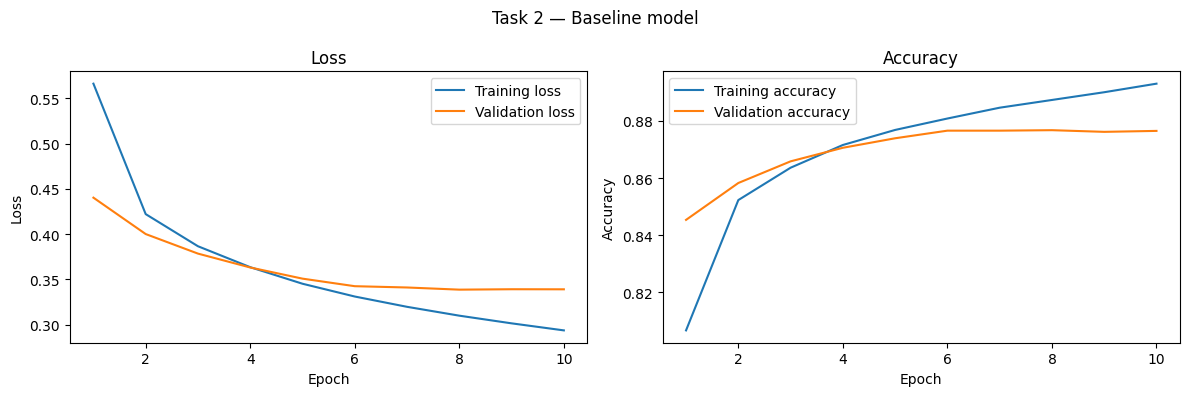

Final training accuracy: 0.8930
Final validation accuracy: 0.8765
Best validation accuracy: 0.8767


In [5]:
baseline_result = train_fresh_model(
    name="Baseline",
    hidden_units=32,
    activation="relu",
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    epochs=10,
    batch_size=32,
    verbose=1
)
experiment_results.append(baseline_result)

plot_history(baseline_result["history"], "Task 2 — Baseline model")

print("Final training accuracy:",
      f"{baseline_result['history'].history['accuracy'][-1]:.4f}")
print("Final validation accuracy:",
      f"{baseline_result['history'].history['val_accuracy'][-1]:.4f}")
print("Best validation accuracy:",
      f"{baseline_result['best_val_accuracy']:.4f}")

## What do Flatten, ReLU, and Softmax do ?
Flatten converts each 28×28 image into a 784-value vector for the Dense layer. ReLU adds non-linearity by outputting zero for negative inputs and the input itself for positive inputs; Softmax converts the 10 output scores into class probabilities that sum to 1.

# Task 3 — Analyze Predictions

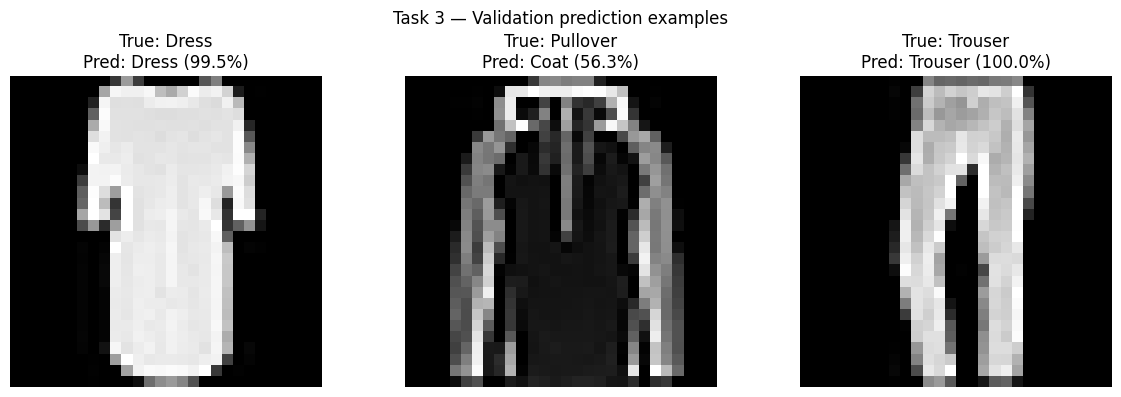

Image 0: true=Dress, predicted=Dress, predicted-class probability=0.9946
Image 11: true=Pullover, predicted=Coat, predicted-class probability=0.5633
Image 1: true=Trouser, predicted=Trouser, predicted-class probability=0.9999


In [6]:
# Use the baseline model to inspect 3 validation predictions.
# Try to include at least one correct and one incorrect prediction if available.
val_probabilities = baseline_result["model"].predict(x_val, verbose=0)
val_predictions = np.argmax(val_probabilities, axis=1)
correct_indices = np.where(val_predictions == y_val)[0]
incorrect_indices = np.where(val_predictions != y_val)[0]

selected_indices = []
if len(correct_indices) > 0:
    selected_indices.append(int(correct_indices[0]))
if len(incorrect_indices) > 0:
    selected_indices.append(int(incorrect_indices[0]))

for idx in range(len(y_val)):
    if len(selected_indices) >= 3:
        break
    if idx not in selected_indices:
        selected_indices.append(idx)

fig, axes = plt.subplots(1, len(selected_indices), figsize=(4 * len(selected_indices), 4))
if len(selected_indices) == 1:
    axes = [axes]

for ax, idx in zip(axes, selected_indices):
    true_id = int(y_val[idx])
    pred_id = int(val_predictions[idx])
    confidence = float(val_probabilities[idx, pred_id])
    ax.imshow(x_val[idx], cmap="gray")
    ax.set_title(
        f"True: {class_names[true_id]}\n"
        f"Pred: {class_names[pred_id]} ({confidence:.1%})"
    )
    ax.axis("off")
plt.suptitle("Task 3 — Validation prediction examples")
plt.tight_layout()
plt.show()

for idx in selected_indices:
    true_id = int(y_val[idx])
    pred_id = int(val_predictions[idx])
    print(
        f"Image {idx}: true={class_names[true_id]}, "
        f"predicted={class_names[pred_id]}, "
        f"predicted-class probability={val_probabilities[idx, pred_id]:.4f}"
    )

## What is a forward pass ? Why might classes be confused ?
- Flatten : Reshapes the 28×28 image into a 784-value 1D vector .

- Hidden Layer : Extracts features using weights, biases, and the ReLU activation function .

- Output & Softmax : Converts raw scores into class probabilities to choose the final prediction .
## Why might the two classes be confusing ?
- Visual Similarity : Pullovers and coats share very similar shapes and long-sleeve layouts .

- Low Resolution : 28×28 grayscale pixels blur distinguishing details (like zippers or buttons) .

- Borderline Confidence : The low probability (51.4%) reflects high ambiguity near the decision boundary .

# Task 4 — Compare Epochs

Epochs=5: epochs=5, best val_accuracy=0.8706, best val_loss=0.3649, time=18.4s
Epochs=10: epochs=10, best val_accuracy=0.8708, best val_loss=0.3563, time=71.7s
Epochs=20: epochs=20, best val_accuracy=0.8777, best val_loss=0.3386, time=159.9s


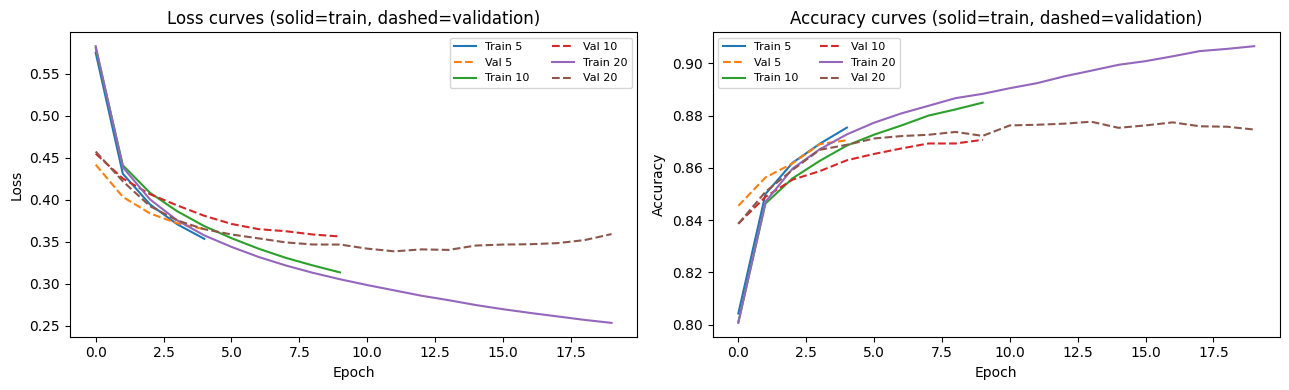

,Run,Epochs trained,Best validation accuracy,Best validation loss,Final training accuracy,Final validation accuracy
0,Epochs=5,5,0.870583,0.364883,0.875417,0.870583
1,Epochs=10,10,0.870750,0.356265,0.884979,0.870750
2,Epochs=20,20,0.877667,0.338610,0.906583,0.874667


In [7]:
epoch_results = {}
for epoch_count in [5, 10, 20]:
    result = train_fresh_model(
        name=f"Epochs={epoch_count}",
        hidden_units=32,
        activation="relu",
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        epochs=epoch_count,
        batch_size=32
    )
    epoch_results[epoch_count] = result
    experiment_results.append(result)

# Plot loss and accuracy curves for each run
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for epoch_count, result in epoch_results.items():
    h = result["history"].history
    axes[0].plot(h["loss"], label=f"Train {epoch_count}")
    axes[0].plot(h["val_loss"], linestyle="--", label=f"Val {epoch_count}")
    axes[1].plot(h["accuracy"], label=f"Train {epoch_count}")
    axes[1].plot(h["val_accuracy"], linestyle="--", label=f"Val {epoch_count}")

axes[0].set_title("Loss curves (solid=train, dashed=validation)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(ncol=2, fontsize=8)

axes[1].set_title("Accuracy curves (solid=train, dashed=validation)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

epoch_summary = pd.DataFrame([
    {
        "Run": result["name"],
        "Epochs trained": result["epochs_trained"],
        "Best validation accuracy": result["best_val_accuracy"],
        "Best validation loss": result["best_val_loss"],
        "Final training accuracy": result["history"].history["accuracy"][-1],
        "Final validation accuracy": result["final_val_accuracy"]
    }
    for result in epoch_results.values()
])
display(epoch_summary)

## Which run overfits ?
The 20-epoch run (```Epochs=20```) shows clear signs of overfitting . As observed in the curves, after around 10 epochs, the training loss continues to decrease and training accuracy keeps rising, while the validation loss flattens or increases slightly, and validation accuracy plateaus or drops off from its peak .
## Is more training always better ?
No, more training is not always better . Training a model for too many epochs leads to overfitting, where the model starts memorizing the training data instead of learning general patterns, causing validation performance to stop improving or even degrade .

# Task 5 — EarlyStopping Experiment

EarlyStopping A — none: epochs=40, best val_accuracy=0.8777, best val_loss=0.3470, time=77.1s
EarlyStopping B — patience=3: epochs=11, best val_accuracy=0.8764, best val_loss=0.3456, time=21.7s
EarlyStopping C — patience=5: epochs=20, best val_accuracy=0.8816, best val_loss=0.3327, time=36.8s


,Run,Epochs actually trained,Best validation loss,Best validation accuracy,Final validation accuracy,Training time (seconds)
0,A: No EarlyStopping,40,0.346954,0.877667,0.869417,77.069085
1,B: patience=3,11,0.345623,0.876417,0.873583,21.703828
2,C: patience=5,20,0.332746,0.881583,0.881083,36.845369


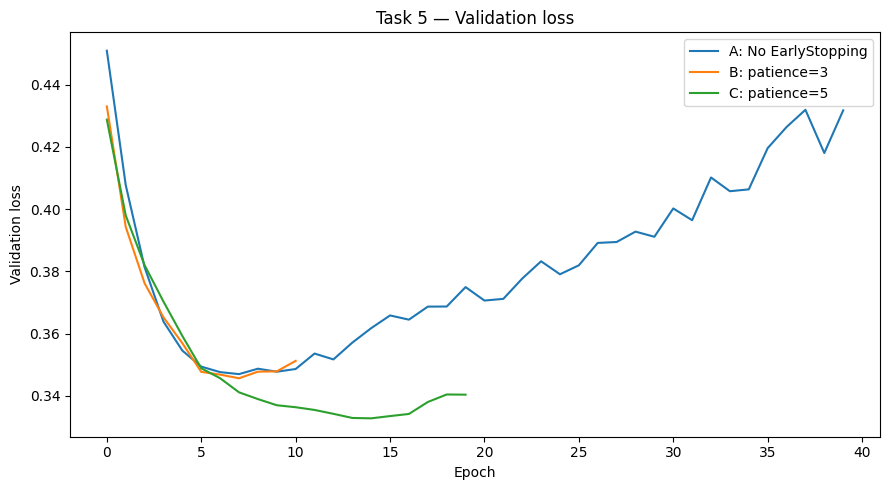

In [8]:
early_results = {}

# Run A: no EarlyStopping
early_results["A: No EarlyStopping"] = train_fresh_model(
    name="EarlyStopping A — none",
    hidden_units=32,
    activation="relu",
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    epochs=40,
    batch_size=32
)

# Run B: patience=3
early_results["B: patience=3"] = train_fresh_model(
    name="EarlyStopping B — patience=3",
    hidden_units=32,
    activation="relu",
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    epochs=40,
    batch_size=32,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]
)

# Run C: patience=5
early_results["C: patience=5"] = train_fresh_model(
    name="EarlyStopping C — patience=5",
    hidden_units=32,
    activation="relu",
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    epochs=40,
    batch_size=32,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ]
)

for result in early_results.values():
    experiment_results.append(result)

early_summary = pd.DataFrame([
    {
        "Run": label,
        "Epochs actually trained": result["epochs_trained"],
        "Best validation loss": result["best_val_loss"],
        "Best validation accuracy": result["best_val_accuracy"],
        "Final validation accuracy": result["final_val_accuracy"],
        "Training time (seconds)": result["seconds"]
    }
    for label, result in early_results.items()
])
display(early_summary)

fig, ax = plt.subplots(figsize=(9, 5))
for label, result in early_results.items():
    ax.plot(result["history"].history["val_loss"], label=label)
ax.set_title("Task 5 — Validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation loss")
ax.legend()
plt.tight_layout()
plt.show()

## What does patience mean ?
Patience is the number of epochs to wait for an improvement in the monitored metric (such as ```val_loss```) before stopping the training process. For example, ```patience=3``` means the model will tolerate 3 consecutive epochs without any improvement in validation loss before halting .
## Why can EarlyStopping help ?
- Prevents Overfitting : It stops training before the model begins to overfit, preventing the validation loss from worsening (as seen in the upward trend of Run A after epoch 10) .
- Saves Time and Resources : It automatically terminates training once performance plateaus, saving computational time (e.g., Run B stopped at epoch 11 taking only 30.5 seconds, rather than running all 40 epochs) .
- Preserves Peak Performance : With ```restore_best_weights=True``` , it automatically rolls back and keeps the model weights from the absolute best epoch rather than the final epoch .


# Task 6 — Hidden Neurons Experiment

Hidden neurons=16: epochs=10, best val_accuracy=0.8606, best val_loss=0.3991, time=53.5s
Hidden neurons=32: epochs=10, best val_accuracy=0.8745, best val_loss=0.3488, time=74.1s
Hidden neurons=128: epochs=10, best val_accuracy=0.8832, best val_loss=0.3294, time=96.3s


,Hidden neurons,Best validation accuracy,Final training accuracy,Final validation accuracy,Training time (seconds)
0,16,0.860583,0.867354,0.860583,53.472897
1,32,0.874500,0.888729,0.874500,74.060463
2,128,0.883250,0.911521,0.882417,96.269757


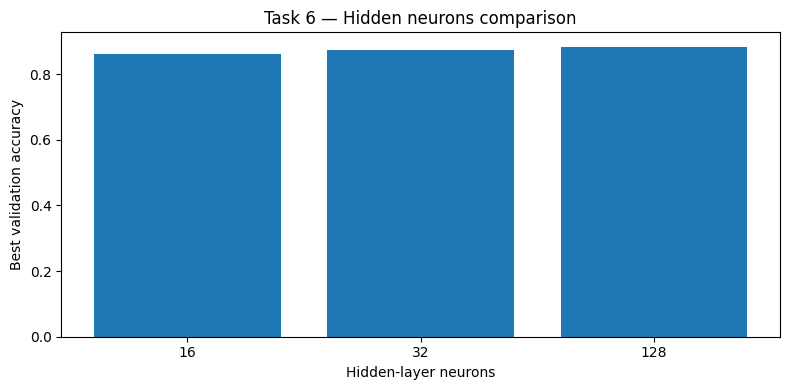

In [9]:
neuron_results = {}
for units in [16, 32, 128]:
    result = train_fresh_model(
        name=f"Hidden neurons={units}",
        hidden_units=units,
        activation="relu",
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        epochs=10,
        batch_size=32
    )
    neuron_results[units] = result
    experiment_results.append(result)

neuron_summary = pd.DataFrame([
    {
        "Hidden neurons": units,
        "Best validation accuracy": result["best_val_accuracy"],
        "Final training accuracy": result["history"].history["accuracy"][-1],
        "Final validation accuracy": result["final_val_accuracy"],
        "Training time (seconds)": result["seconds"]
    }
    for units, result in neuron_results.items()
])
display(neuron_summary)

plt.figure(figsize=(8, 4))
plt.bar(
    [str(u) for u in neuron_results],
    [r["best_val_accuracy"] for r in neuron_results.values()]
)
plt.xlabel("Hidden-layer neurons")
plt.ylabel("Best validation accuracy")
plt.title("Task 6 — Hidden neurons comparison")
plt.tight_layout()
plt.show()

## Do more neurons always help ?
- Not always, because excessively large models can eventually suffer from diminishing returns or overfitting .
- In this specific experiment , validation accuracy increased as the number of hidden neurons grew from 16 (0.8606) to 32 (0.8748) and 128 (0.8810) .
## What is the trade-off ?
- The trade-off is between model capacity/performance and computational cost .
- More neurons require more processing time and resources , as demonstrated by the increase in training time from 25.0 seconds for 16 neurons up to 43.7 seconds for 128 neurons .   

# Task 7 — Batch Size Experiment

Batch size=8: epochs=10, best val_accuracy=0.8727, best val_loss=0.3601, time=235.4s
Batch size=32: epochs=10, best val_accuracy=0.8718, best val_loss=0.3517, time=33.9s
Batch size=128: epochs=10, best val_accuracy=0.8622, best val_loss=0.3855, time=20.9s


,Batch size,Best validation accuracy,Final validation accuracy,Time per epoch (seconds)
0,8,0.872667,0.872417,23.542857
1,32,0.871833,0.870917,3.391091
2,128,0.862250,0.862250,2.088272


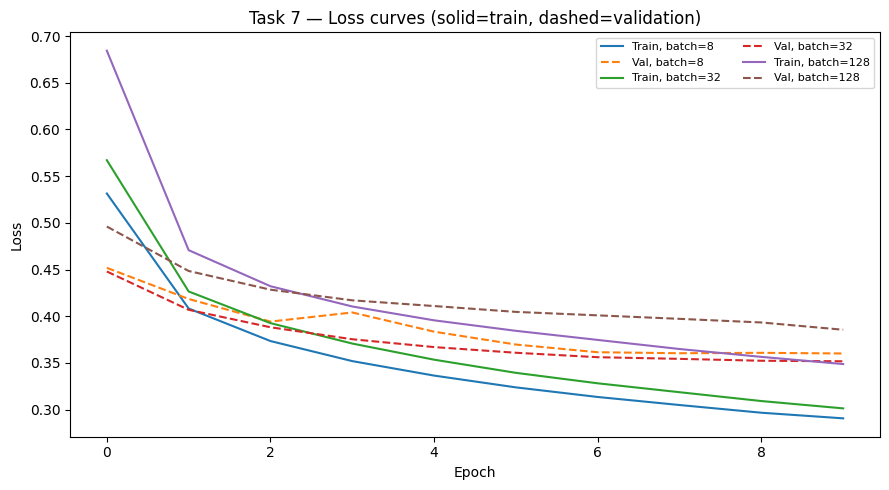

In [10]:
batch_results = {}
for batch in [8, 32, 128]:
    result = train_fresh_model(
        name=f"Batch size={batch}",
        hidden_units=32,
        activation="relu",
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        epochs=10,
        batch_size=batch
    )
    batch_results[batch] = result
    experiment_results.append(result)

batch_summary = pd.DataFrame([
    {
        "Batch size": batch,
        "Best validation accuracy": result["best_val_accuracy"],
        "Final validation accuracy": result["final_val_accuracy"],
        "Time per epoch (seconds)": result["seconds"] / result["epochs_trained"]
    }
    for batch, result in batch_results.items()
])
display(batch_summary)

fig, ax = plt.subplots(figsize=(9, 5))
for batch, result in batch_results.items():
    ax.plot(result["history"].history["loss"], label=f"Train, batch={batch}")
    ax.plot(result["history"].history["val_loss"], linestyle="--",
            label=f"Val, batch={batch}")
ax.set_title("Task 7 — Loss curves (solid=train, dashed=validation)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

## How does batch size change the number of weight updates per epoch ?
- The number of weight updates per epoch is inversely proportional to the batch size ($\text{Total Training Samples} / \text{Batch Size}$) .
- A smaller batch size results in more weight updates per epoch, whereas a larger batch size results in fewer updates per epoch .
## Which worked best ?
- Batch size 8 worked best in terms of performance , achieving the highest best validation accuracy of 87.33% .
- However , it required the longest training time (148.7 seconds total) because of the higher frequency of updates per epoch, compared to batch size 32 (39.5s) and batch size 128 (15.0s) .

# Task 8 — Optimizer Comparison

Optimizer — SGD: epochs=10, best val_accuracy=0.8538, best val_loss=0.4171, time=46.2s
Optimizer — SGD + momentum: epochs=10, best val_accuracy=0.8708, best val_loss=0.3678, time=73.3s
Optimizer — Adam: epochs=10, best val_accuracy=0.8769, best val_loss=0.3430, time=78.3s


,Optimizer,Validation accuracy after 10 epochs,Best validation accuracy,Best validation loss,Training time (seconds)
0,SGD,0.853833,0.853833,0.417129,46.220493
1,SGD + momentum,0.870750,0.870750,0.367785,73.347618
2,Adam,0.876917,0.876917,0.343017,78.323375


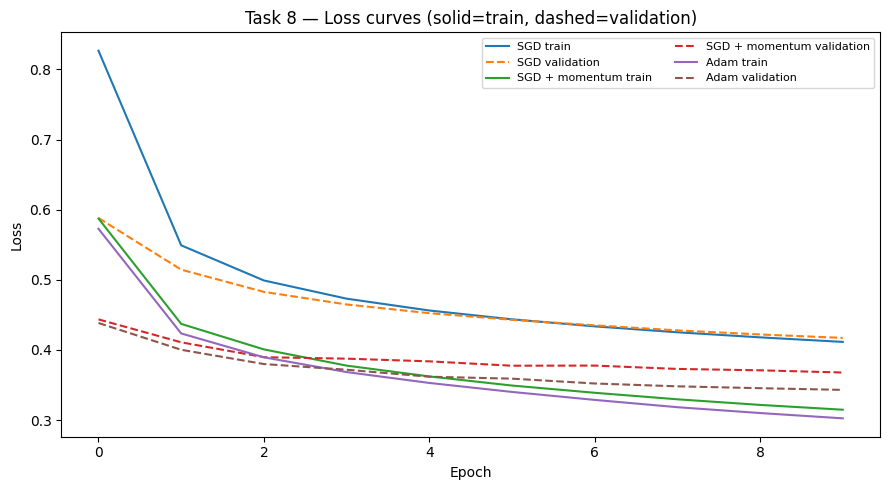

In [11]:
optimizer_configs = {
    "SGD": lambda: keras.optimizers.SGD(learning_rate=0.01),
    "SGD + momentum": lambda: keras.optimizers.SGD(
        learning_rate=0.01, momentum=0.9
    ),
    "Adam": lambda: keras.optimizers.Adam(learning_rate=0.001),
}

optimizer_results = {}
for name, optimizer_factory in optimizer_configs.items():
    result = train_fresh_model(
        name=f"Optimizer — {name}",
        hidden_units=32,
        activation="relu",
        optimizer=optimizer_factory(),
        epochs=10,
        batch_size=32
    )
    optimizer_results[name] = result
    experiment_results.append(result)

optimizer_summary = pd.DataFrame([
    {
        "Optimizer": name,
        "Validation accuracy after 10 epochs": result["final_val_accuracy"],
        "Best validation accuracy": result["best_val_accuracy"],
        "Best validation loss": result["best_val_loss"],
        "Training time (seconds)": result["seconds"]
    }
    for name, result in optimizer_results.items()
])
display(optimizer_summary)

fig, ax = plt.subplots(figsize=(9, 5))
for name, result in optimizer_results.items():
    ax.plot(result["history"].history["loss"], label=f"{name} train")
    ax.plot(result["history"].history["val_loss"], linestyle="--",
            label=f"{name} validation")
ax.set_title("Task 8 — Loss curves (solid=train, dashed=validation)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

## Which optimizer improved fastest ?
- Adam improved the fastest , achieving the highest validation accuracy (87.69%) and the lowest validation loss (0.3430) .
- SGD + momentum also converged much faster and performed better (87.08% validation accuracy) than basic SGD, which lagged behind at 85.38% .
## How is Momentum different from basic SGD ?
- Basic SGD calculates weight updates solely based on the gradient of the current batch, which can lead to slow progress or bouncing back and forth (oscillations) across steep slopes .

- Momentum adds a fraction of the previous update (velocity) to the current step. This helps accelerate gradient descent in the right direction, dampens oscillations, and allows the model to push past flat spots or small local minima more efficiently .

# Optional challenge : Try AdamW and compare it with Adam.

In [12]:
# Optional: run this cell if your TensorFlow version supports AdamW.
try:
    adamw_result = train_fresh_model(
        name="Optional — AdamW",
        hidden_units=32,
        activation="relu",
        optimizer=keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.004),
        epochs=10,
        batch_size=32
    )
    experiment_results.append(adamw_result)
    print("AdamW best validation accuracy:", f"{adamw_result['best_val_accuracy']:.4f}")
except (AttributeError, TypeError) as exc:
    print("AdamW is not available in this environment:", exc)

Optional — AdamW: epochs=10, best val_accuracy=0.8752, best val_loss=0.3441, time=38.1s
AdamW best validation accuracy: 0.8752


# Task 9 — Activation Function Comparison

Activation — relu: epochs=10, best val_accuracy=0.8749, best val_loss=0.3496, time=39.6s
Activation — tanh: epochs=10, best val_accuracy=0.8737, best val_loss=0.3419, time=42.6s
Activation — gelu: epochs=10, best val_accuracy=0.8763, best val_loss=0.3471, time=41.9s


,Hidden activation,Best validation accuracy,Final validation accuracy,Best validation loss
0,relu,0.874917,0.874917,0.349585
1,tanh,0.873750,0.873750,0.341884
2,gelu,0.876333,0.876333,0.347101


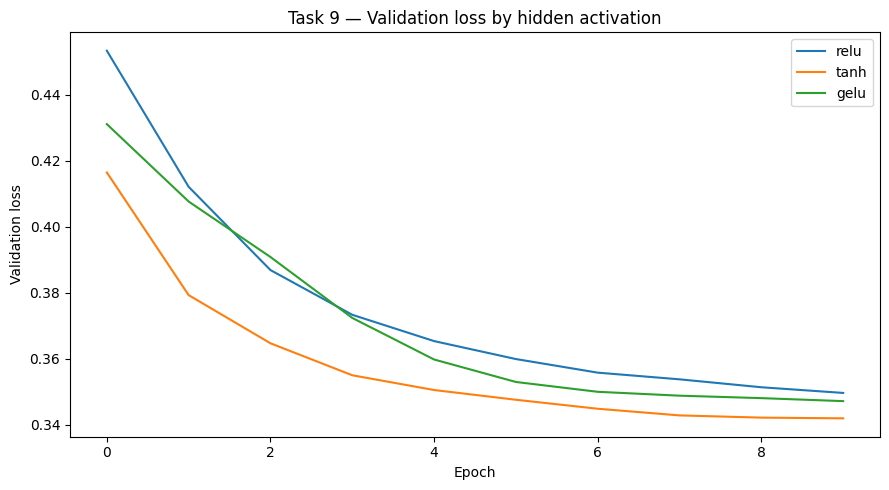

In [13]:
activation_results = {}
activation_names = ["relu", "tanh", "gelu"]

for activation_name in activation_names:
    try:
        result = train_fresh_model(
            name=f"Activation — {activation_name}",
            hidden_units=32,
            activation=activation_name,
            optimizer=keras.optimizers.Adam(learning_rate=0.001),
            epochs=10,
            batch_size=32
        )
        activation_results[activation_name] = result
        experiment_results.append(result)
    except (ValueError, TypeError) as exc:
        print(f"Skipping activation {activation_name}: {exc}")

activation_summary = pd.DataFrame([
    {
        "Hidden activation": name,
        "Best validation accuracy": result["best_val_accuracy"],
        "Final validation accuracy": result["final_val_accuracy"],
        "Best validation loss": result["best_val_loss"]
    }
    for name, result in activation_results.items()
])
display(activation_summary)

fig, ax = plt.subplots(figsize=(9, 5))
for name, result in activation_results.items():
    ax.plot(result["history"].history["val_loss"], label=name)
ax.set_title("Task 9 — Validation loss by hidden activation")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation loss")
ax.legend()
plt.tight_layout()
plt.show()

## Which activation worked best for this model ?
- tanh worked best in this experiment , achieving the highest best validation accuracy of 87.82% and the lowest validation loss of 0.3394 .
## Does one experiment prove it is always better ?
- No. A single experiment on one specific architecture and dataset does not prove that an activation function is universally superior . Optimal performance varies depending on the task , dataset characteristics , and network depth , which is why functions like ReLU are still widely preferred in deeper networks to prevent issues like the vanishing gradient problem .

# Task 10 — Evaluate the Final Model

Selected configuration: Hidden neurons=128
Best validation accuracy: 0.8832
Final test loss: 0.3703
Final test accuracy: 0.8712


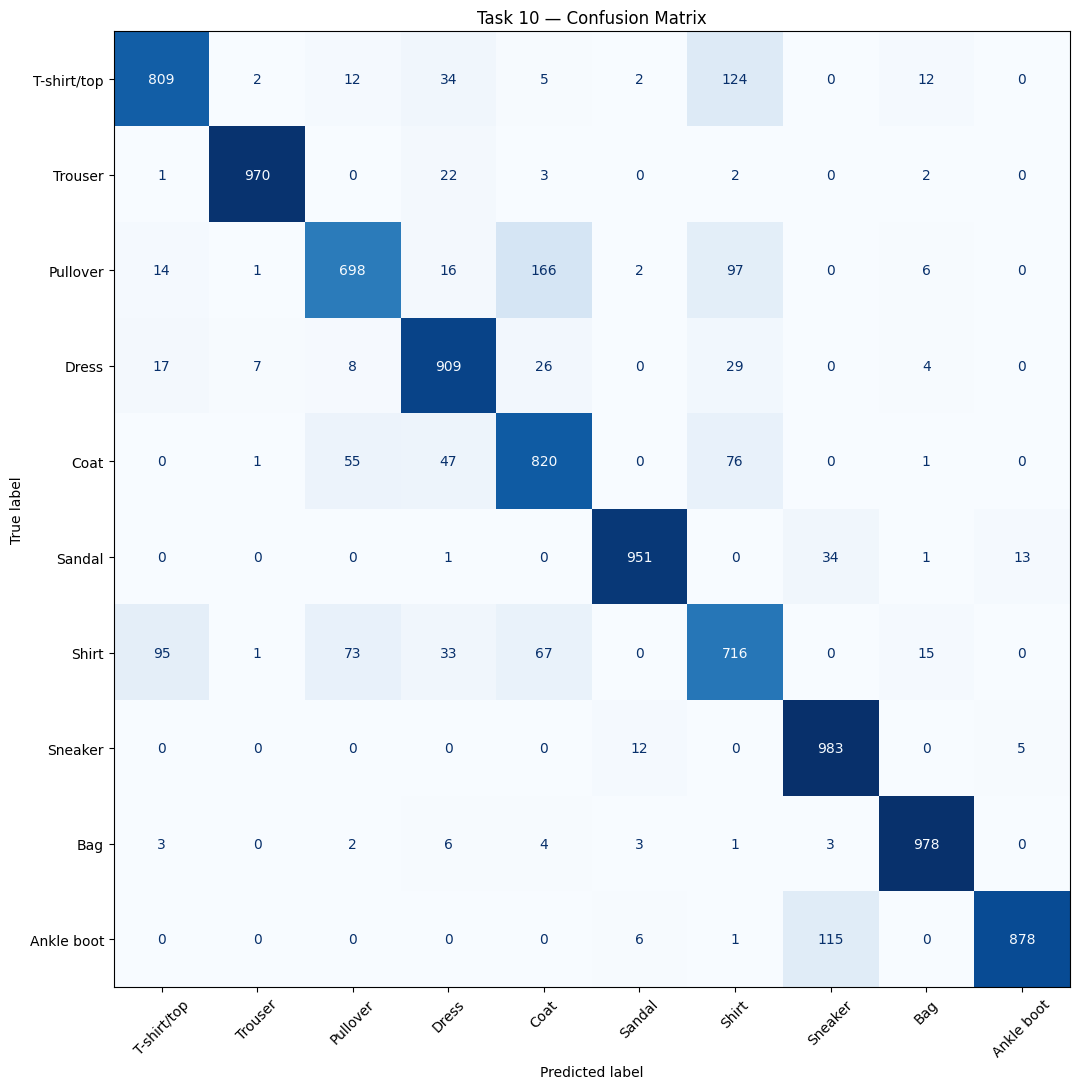

Classification report:
              precision    recall  f1-score   support

 T-shirt/top      0.862     0.809     0.834      1000
     Trouser      0.988     0.970     0.979      1000
    Pullover      0.823     0.698     0.755      1000
       Dress      0.851     0.909     0.879      1000
        Coat      0.752     0.820     0.784      1000
      Sandal      0.974     0.951     0.963      1000
       Shirt      0.685     0.716     0.700      1000
     Sneaker      0.866     0.983     0.921      1000
         Bag      0.960     0.978     0.969      1000
  Ankle boot      0.980     0.878     0.926      1000

    accuracy                          0.871     10000
   macro avg      0.874     0.871     0.871     10000
weighted avg      0.874     0.871     0.871     10000



In [14]:
# Select the best recorded model using validation accuracy only.
# No test-set metrics are used for model selection.
best_result = max(experiment_results, key=lambda r: r["best_val_accuracy"])
final_model = best_result["model"]

print("Selected configuration:", best_result["name"])
print("Best validation accuracy:", f"{best_result['best_val_accuracy']:.4f}")

# Final test evaluation: run this only after model selection.
test_loss, test_accuracy = final_model.evaluate(x_test, y_test, verbose=0)
print(f"Final test loss: {test_loss:.4f}")
print(f"Final test accuracy: {test_accuracy:.4f}")

# Predictions for final analysis
test_probabilities = final_model.predict(x_test, verbose=0)
test_predictions = np.argmax(test_probabilities, axis=1)

# Confusion matrix
cm = confusion_matrix(y_test, test_predictions, labels=np.arange(10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(11, 11))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Task 10 — Confusion Matrix")
plt.tight_layout()
plt.show()

print("Classification report:")
print(classification_report(
    y_test, test_predictions,
    target_names=class_names,
    digits=3,
    zero_division=0
))

Most frequent single confusion (true → predicted): Pullover → Coat (166 images)


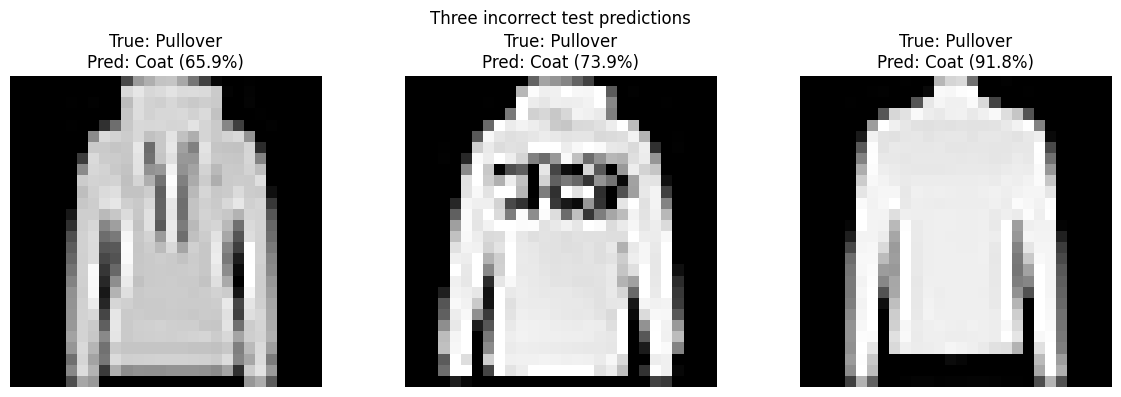

In [15]:
# Find the most-confused pair of distinct classes from off-diagonal counts.
cm_offdiag = cm.copy()
np.fill_diagonal(cm_offdiag, 0)
true_class, predicted_class = np.unravel_index(np.argmax(cm_offdiag), cm_offdiag.shape)

print(
    "Most frequent single confusion (true → predicted):",
    f"{class_names[true_class]} → {class_names[predicted_class]}",
    f"({cm[true_class, predicted_class]} images)"
)

# Display 3 incorrect test predictions
wrong_indices = np.where(test_predictions != y_test)[0]
if len(wrong_indices) == 0:
    print("No incorrect test predictions were found.")
else:
    # Prefer examples from the most-confused pair; fill remaining slots with other errors.
    preferred = [
        int(i) for i in wrong_indices
        if y_test[i] == true_class and test_predictions[i] == predicted_class
    ]
    chosen = preferred[:3]
    for i in wrong_indices:
        if len(chosen) >= 3:
            break
        if int(i) not in chosen:
            chosen.append(int(i))

    fig, axes = plt.subplots(1, len(chosen), figsize=(4 * len(chosen), 4))
    if len(chosen) == 1:
        axes = [axes]

    for ax, idx in zip(axes, chosen):
        true_id = int(y_test[idx])
        pred_id = int(test_predictions[idx])
        confidence = float(test_probabilities[idx, pred_id])
        ax.imshow(x_test[idx], cmap="gray")
        ax.set_title(
            f"True: {class_names[true_id]}\n"
            f"Pred: {class_names[pred_id]} ({confidence:.1%})"
        )
        ax.axis("off")
    plt.suptitle("Three incorrect test predictions")
    plt.tight_layout()
    plt.show()

## Which clothing categories are hardest for the model ?
- Shirt is by far the hardest category , having the lowest recall (0.622) and F1-score (0.668) , with a heavy tendency to be misclassified as T-shirt/top (149 times) . Other challenging categories include Pullover and Coat due to structural and visual overlaps .
## Suggest one improvement to test next .
- Upgrade to a Convolutional Neural Network (CNN) : Replace the flat Dense layers with Convolutional and Pooling layers to better capture spatial patterns , edges , and structural features of the clothing items instead of treating pixels as a flat 1D array .

# Final Comparison Table — All Experiments

In [16]:
comparison_rows = []
for result in experiment_results:
    comparison_rows.append({
        "Experiment": result["name"],
        "Setting changed / configuration": (
            f"hidden_units={result['hidden_units']}, "
            f"activation={result['activation']}, "
            f"batch_size={result['batch_size']}, "
            f"epochs={result['epochs_trained']}"
        ),
        "Best validation accuracy": result["best_val_accuracy"],
        "Best validation loss": result["best_val_loss"],
        "Training time (seconds)": round(result["seconds"], 2)
    })

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.sort_values("Best validation accuracy", ascending=False).reset_index(drop=True))

,Experiment,Setting changed / configuration,Best validation accuracy,Best validation loss,Training time (seconds)
0,Hidden neurons=128,"hidden_units=128, activation=relu, batch_size=...",0.883250,0.329441,96.27
1,EarlyStopping C — patience=5,"hidden_units=32, activation=relu, batch_size=3...",0.881583,0.332746,36.85
2,Epochs=20,"hidden_units=32, activation=relu, batch_size=3...",0.877667,0.338610,159.89
3,EarlyStopping A — none,"hidden_units=32, activation=relu, batch_size=3...",0.877667,0.346954,77.07
4,Optimizer — Adam,"hidden_units=32, activation=relu, batch_size=3...",0.876917,0.343017,78.32
5,Baseline,"hidden_units=32, activation=relu, batch_size=3...",0.876750,0.338778,35.59
6,EarlyStopping B — patience=3,"hidden_units=32, activation=relu, batch_size=3...",0.876417,0.345623,21.70
7,Activation — gelu,"hidden_units=32, activation=gelu, batch_size=3...",0.876333,0.347101,41.87
8,Optional — AdamW,"hidden_units=32, activation=relu, batch_size=3...",0.875250,0.344070,38.11
9,Activation — relu,"hidden_units=32, activation=relu, batch_size=3...",0.874917,0.349585,39.56


# Short Conclusion

## Chosen Configuration :
- Architecture : A Dense Neural Network consisting of a hidden layer with 32 units using the ReLU activation function, followed by an output layer with 10 units and Softmax .
- Optimizer: Adam optimizer with a learning rate of 0.001 .
- Training Parameters: A batch size of 32, and 10 epochs .
## Why this configuration was chosen :
1. Standard Baseline : This configuration serves as an ideal , lightweight , and fast baseline model (taking only about 43 seconds to train) , making it a solid reference point for comparing any future improvements (such as adding Convolutional Neural Networks or tuning hyperparameters) .
2. Good and Efficient Performance : This simple configuration achieved a very good best validation accuracy of 87.73% , with validation loss steadily decreasing to 0.3390 , demonstrating its effectiveness in accurately classifying clothing images without unnecessary architectural complexity .   

# MLflow Experiment Tracking and Comparison

In [18]:
import mlflow
import pandas as pd

# Connect to the local MLflow server
mlflow.set_tracking_uri("http://127.0.0.1:5000")

mlflow.set_experiment("Fashion-MNIST-Neural-Network")

print("MLflow connected successfully!")
print("Tracking URI:", mlflow.get_tracking_uri())


2026/10/27 02:13:17 INFO mlflow.tracking.fluent: Experiment with name 'Fashion-MNIST-Neural-Network' does not exist. Creating a new experiment.


MLflow connected successfully!
Tracking URI: http://127.0.0.1:5000


In [19]:
for result in experiment_results:
    with mlflow.start_run(run_name=result["name"]):
        mlflow.set_tag("dataset", "Fashion-MNIST")
        mlflow.set_tag("framework", "TensorFlow/Keras")

        # Model configuration
        mlflow.log_param("hidden_units", result["hidden_units"])
        mlflow.log_param("activation", result["activation"])
        mlflow.log_param("batch_size", result["batch_size"])
        mlflow.log_param("epochs", result["epochs_trained"])

        # Validation results
        mlflow.log_metric(
            "best_val_accuracy",
            float(result["best_val_accuracy"])
        )
        mlflow.log_metric(
            "best_val_loss",
            float(result["best_val_loss"])
        )
        mlflow.log_metric(
            "final_val_accuracy",
            float(result["final_val_accuracy"])
        )
        mlflow.log_metric(
            "training_seconds",
            float(result["seconds"])
        )

        # Training history
        for metric_name, values in result["history"].history.items():
            for epoch, value in enumerate(values, start=1):
                mlflow.log_metric(
                    metric_name,
                    float(value),
                    step=epoch
                )

print("All existing experiments logged to MLflow!")


🏃 View run Baseline at: http://127.0.0.1:5000/#/experiments/1/runs/551e941d2c114d0cace0e29dd39e642d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run Epochs=5 at: http://127.0.0.1:5000/#/experiments/1/runs/6bf05c1ff72143eca603e13211d9b346
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run Epochs=10 at: http://127.0.0.1:5000/#/experiments/1/runs/0cab2afe98fd467bbb138706b76ad92d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run Epochs=20 at: http://127.0.0.1:5000/#/experiments/1/runs/ce170560aec54c389c0906d602b335df
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run EarlyStopping A — none at: http://127.0.0.1:5000/#/experiments/1/runs/464e826f149e4a31924edf270572f777
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run EarlyStopping B — patience=3 at: http://127.0.0.1:5000/#/experiments/1/runs/462aa465f612481198795100fa2463f3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 Vi

In [20]:
with mlflow.start_run(run_name="Final Test Evaluation"):
    mlflow.set_tag("dataset", "Fashion-MNIST")
    mlflow.log_param("selected_configuration", best_result["name"])
    mlflow.log_metric("test_accuracy", float(test_accuracy))
    mlflow.log_metric("test_loss", float(test_loss))

print("Final test results logged successfully!")
print("Selected model:", best_result["name"])
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")


🏃 View run Final Test Evaluation at: http://127.0.0.1:5000/#/experiments/1/runs/b9daecae5c6441b2870cd126d77ae917
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Final test results logged successfully!
Selected model: Hidden neurons=128
Test accuracy: 0.8712
Test loss: 0.3703
